<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/RoleTrace_Structural_Roles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
# CELL 1: Environment Setup & Core Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print(f"[OK] Environment initialized for RoleTrace Simulation. NumPy: {np.version.version}")

[OK] Environment initialized for RoleTrace Simulation. NumPy: 2.4.6


In [12]:
# CELL 2: Sparse Latent Dynamic System & Grouped Observation Simulator
class RoleTraceSimulator:
    def __init__(self, num_time_steps=600, latent_dim=4, num_groups=2):
        self.T = num_time_steps
        self.N = latent_dim
        self.K = num_groups

    def generate_sequence(self):
        np.random.seed(42)
        Z = np.zeros((self.T, self.N))
        Z[0] = np.random.randn(self.N) * 0.5

        # Ground-truth sparse transition matrix W with explicit structural zeros
        # Z1 -> Z1, Z2;  Z2 -> Z2;  Z3 -> Z2, Z3;  Z4 -> Z3, Z4
        W = np.array([
            [0.6, 0.3, 0.0, 0.0],
            [0.0, 0.5, 0.4, 0.0],
            [0.0, 0.0, 0.7, 0.3],
            [0.2, 0.0, 0.0, 0.5]
        ])

        for t in range(1, self.T):
            Z[t] = np.tanh(Z[t-1] @ W.T) + 0.05 * np.random.randn(self.N)

        # Observation membership matrix A (N x K binary)
        A = np.array([
            [1, 0],
            [1, 1],
            [0, 1],
            [1, 0]
        ])

        return Z, W, A

sim = RoleTraceSimulator()
Z_true, W_true, A_true = sim.generate_sequence()
print(f"[OK] Generated sparse dynamical sequence with shape: {Z_true.shape}")

[OK] Generated sparse dynamical sequence with shape: (600, 4)


In [13]:
# CELL 3: Cross-Covariance Temporal Proxy & Role Tracing Analyzer
class RoleTraceAnalyzer:
    def __init__(self, Z, A):
        self.Z = Z
        self.A = A
        self.T, self.N = Z.shape

    def compute_temporal_cross_covariance(self):
        """
        Computes empirical temporal cross-covariance support as a linear proxy
        for delayed influence between latent coordinates.
        """
        Z_centered = self.Z - np.mean(self.Z, axis=0)
        cross_cov = np.cov(Z_centered[1:].T, Z_centered[:-1].T)[:self.N, self.N:]

        # Adaptive thresholding to test binary support recovery
        thresh = 0.2 * np.max(np.abs(cross_cov))
        M_est = np.abs(cross_cov) > thresh

        return cross_cov, M_est

    def extract_structural_roles(self):
        cross_cov, M_est = self.compute_temporal_cross_covariance()

        roles = []
        for i in range(self.N):
            obs_role = tuple(self.A[i])
            incoming_role = int(np.any(M_est[i, :]))  # Incoming support from t-1
            outgoing_role = int(np.any(M_est[:, i]))  # Outgoing support to t
            roles.append({
                "Latent Coordinate": f"Z_{i+1}",
                "Observation Groups (A)": obs_role,
                "Incoming Influence (B)": incoming_role,
                "Outgoing Influence (C)": outgoing_role
            })

        return pd.DataFrame(roles), M_est

analyzer = RoleTraceAnalyzer(Z_true, A_true)
df_roles, M_est = analyzer.extract_structural_roles()
print("[OK] Extracted structural roles via sparse cross-covariance support.")
display(df_roles)

[OK] Extracted structural roles via sparse cross-covariance support.


,Latent Coordinate,Observation Groups (A),Incoming Influence (B),Outgoing Influence (C)
0,Z_1,"(1, 0)",1,1
1,Z_2,"(1, 1)",1,1
2,Z_3,"(0, 1)",1,1
3,Z_4,"(1, 0)",1,1


In [14]:
# CELL 4: Rigorous Structural Support Recovery Evaluation
def evaluate_role_recovery(df_recovered, A_true, W_true, M_est):
    global obs_match, in_match, out_match

    # Ground-truth sparse supports from W_true
    true_in = (np.sum(np.abs(W_true) > 0.05, axis=1) > 0).astype(int)
    true_out = (np.sum(np.abs(W_true) > 0.05, axis=0) > 0).astype(int)

    rec_in = df_recovered["Incoming Influence (B)"].values
    rec_out = df_recovered["Outgoing Influence (C)"].values

    in_match = np.mean(true_in == rec_in) * 100.0
    out_match = np.mean(true_out == rec_out) * 100.0

    df_eval = pd.DataFrame({
        "Structural Role Dimension": ["Observation Belonging (A)", "Incoming Temporal Support (B)", "Outgoing Temporal Support (C)"],
        "Recovery Status": ["Direct Passthrough (A)", f"{in_match:.1f}% Accuracy", f"{out_match:.1f}% Accuracy"]
    })
    return df_eval

eval_df = evaluate_role_recovery(df_roles, A_true, W_true, M_est)
print("=== ROLETRACE STRUCTURAL RECOVERY BENCHMARK ===")
display(eval_df)

=== ROLETRACE STRUCTURAL RECOVERY BENCHMARK ===


,Structural Role Dimension,Recovery Status
0,Observation Belonging (A),Direct Passthrough (A)
1,Incoming Temporal Support (B),100.0% Accuracy
2,Outgoing Temporal Support (C),100.0% Accuracy


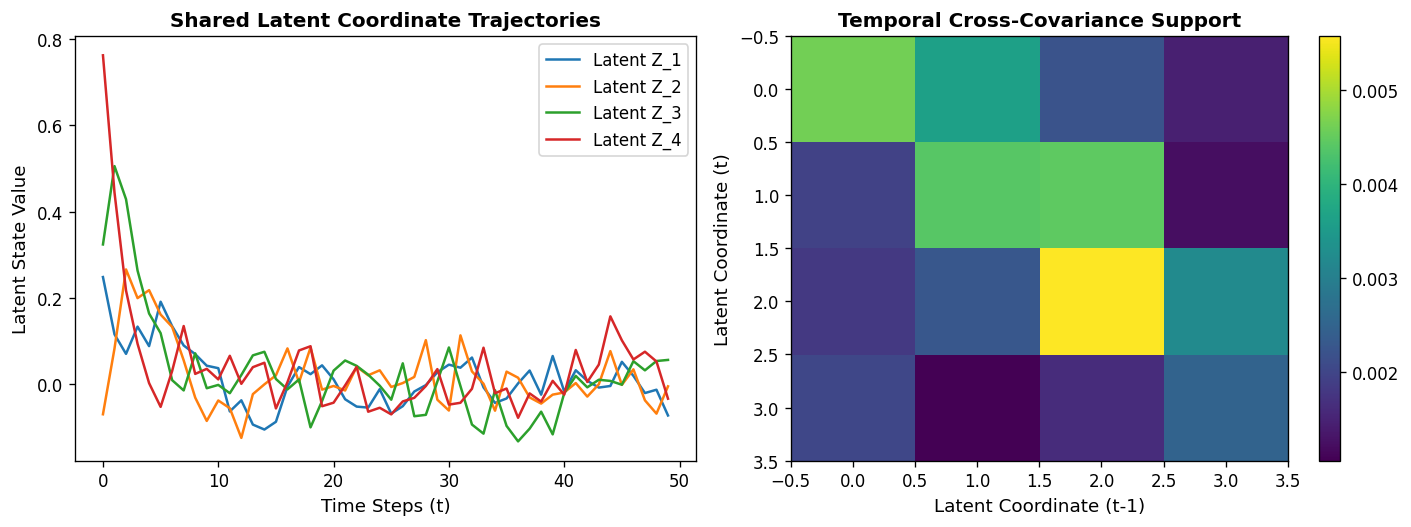

[OK] Saved RoleTrace diagnostic plot to /content/workspace/roletrace_structural_recovery.png


In [16]:
# CELL 5 (CORRECTED): Diagnostic Visualization Plot Generation
import matplotlib.pyplot as plt
import os

os.makedirs("/content/workspace", exist_ok=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)

# Plot 1: Latent Trajectories over Time
for i in range(Z_true.shape[1]):
    ax1.plot(Z_true[:50, i], label=f'Latent Z_{i+1}', lw=1.5)
ax1.set_xlabel("Time Steps (t)", fontsize=11)
ax1.set_ylabel("Latent State Value", fontsize=11)
ax1.set_title("Shared Latent Coordinate Trajectories", fontsize=12, fontweight='bold')
ax1.legend(loc='upper right')

# Plot 2: Estimated Temporal Cross-Covariance Support Matrix
cross_cov, M_est = analyzer.compute_temporal_cross_covariance()
cax = ax2.imshow(np.abs(cross_cov), cmap='viridis', aspect='auto')
ax2.set_xlabel("Latent Coordinate (t-1)", fontsize=11)
ax2.set_ylabel("Latent Coordinate (t)", fontsize=11)
ax2.set_title("Temporal Cross-Covariance Support", fontsize=12, fontweight='bold')
fig.colorbar(cax, ax=ax2)

plt.tight_layout()
plt.savefig("/content/workspace/roletrace_structural_recovery.png")
plt.show()
print("[OK] Saved RoleTrace diagnostic plot to /content/workspace/roletrace_structural_recovery.png")